<a href="https://colab.research.google.com/github/prattayabsmrstu/Wetland_Advance/blob/main/Copy_of_Wetlands_final_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import ee

try:
    project_id = 'wetland-514509'
    ee.Initialize(project=project_id)
    print("Google Earth Engine successfully initialized with project ID wetland-514509.")
except Exception as e:
    print("Authentication required. Please authenticate your account.")
    ee.Authenticate()
    ee.Initialize(project=project_id)
    print("Authentication and initialization completed successfully.")

# গোপালগঞ্জ জেলার বাউন্ডারি নির্ধারণ
gopalganj = ee.FeatureCollection("FAO/GAUL/2015/level2") \
    .filter(ee.Filter.eq("ADM0_NAME", "Bangladesh")) \
    .filter(ee.Filter.eq("ADM2_NAME", "Gopalganj"))

# সেন্টিনেল ওয়ান সার ডেটাসেট ফিল্টার করা
s1_collection = ee.ImageCollection("COPERNICUS/S1_GRD") \
    .filterBounds(gopalganj) \
    .filterDate("2025-01-01", "2025-12-31") \
    .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH")) \
    .filter(ee.Filter.eq("instrumentMode", "IW"))

# ইমেজ কম্পোজিট তৈরি এবং ক্লিপ করা
s1_image = s1_collection.select("VH").mean().clip(gopalganj)

print("Gopalganj spatial boundary and Sentinel data extraction prepared successfully.")

Google Earth Engine successfully initialized with project ID wetland-514509.
Gopalganj spatial boundary and Sentinel data extraction prepared successfully.


In [10]:
import ee

# ১. আধুনিক GAUL লেভেল ২ ডেটাসেট ব্যবহার করে গোপালগঞ্জ জেলার বাউন্ডারি নির্ধারণ
gopalganj = ee.FeatureCollection("FAO/GAUL/2025/level2") \
    .filter(ee.Filter.eq("ADM0_NAME", "Bangladesh")) \
    .filter(ee.Filter.eq("ADM2_NAME", "Gopalganj"))

# ২. সেন্টিনেল ওয়ান সার (Sentinel-1 SAR) ডেটাসেট ফিল্টার ও ওয়াটার মাস্ক এক্সট্রাকশন
s1_collection = ee.ImageCollection("COPERNICUS/S1_GRD") \
    .filterBounds(gopalganj) \
    .filterDate("2025-01-01", "2025-12-31") \
    .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH")) \
    .filter(ee.Filter.eq("instrumentMode", "IW"))

# ভিএইচ ব্যান্ডের মিন কম্পোজিট তৈরি এবং ক্লিপ করা
s1_image = s1_collection.select("VH").mean().clip(gopalganj)

# ওটসু থ্রেশহোল্ডিং বা নির্দিষ্ট থ্রেশহোল্ড (যেমন: -15 dB) ব্যবহার করে ওয়াটার বডি আইসোলেশন
# সাধারণত SAR ব্যাকস্ক্যাটারের ক্ষেত্রে কম মান (Dark pixels) পানি নির্দেশ করে
water_mask = s1_image.lt(-15).rename('water_extent')

# ৩. কোপারনিকাস DEM (30m) থেকে এলিভেশন এবং স্লোপ এক্সট্রাকশন
dem = ee.Image("COPERNICUS/DEM/GLO30").select('DEM').clip(gopalganj)
slope = ee.Terrain.slope(dem).rename('slope')

# ৪. সম্মিলিত স্ট্যাক তৈরি (PINN মডেলের ইনপুট স্প্যাশিয়াল ডেটার জন্য)
model_spatial_features = dem.addBands(slope).addBands(water_mask).addBands(s1_image.rename('sar_vh'))

print("Step 2 Completed: Topographic DEM, Slope, and SAR-derived Water Mask successfully generated for Gopalganj.")

Step 2 Completed: Topographic DEM, Slope, and SAR-derived Water Mask successfully generated for Gopalganj.


In [29]:
import ee
import geemap

# ১. প্রজেক্ট ইনিশিয়ালাইজেশন
project_id = 'wetland-514509'
try:
    ee.Initialize(project=project_id)
except Exception as e:
    ee.Authenticate()
    ee.Initialize(project=project_id)

# ২. গোপালগঞ্জ জেলার প্রশাসনিক বাউন্ডারি (FAO GAUL 2015 ডেটাসেট)
gopalganj = ee.FeatureCollection("FAO/GAUL/2015/level2") \
    .filter(ee.Filter.eq("ADM0_NAME", "Bangladesh")) \
    .filter(ee.Filter.eq("ADM2_NAME", "Gopalganj"))

# ৩. সেন্টিনেল-১ সার ডেটাসেট (২০১৫ থেকে ২০২৫) ফিল্টার ও ওয়াটার মাস্ক এক্সট্রাকশন
s1_collection = ee.ImageCollection("COPERNICUS/S1_GRD") \
    .filterBounds(gopalganj) \
    .filterDate("2015-01-01", "2025-12-31") \
    .filter(ee.Filter.eq('instrumentMode', 'IW')) \
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))

count = s1_collection.size().getInfo()
print(f"Total Sentinel-1 images found (2015-2025): {count}")

if count > 0:
    s1_image = s1_collection.select("VH").mean().clip(gopalganj)
    water_mask = s1_image.lt(-15).rename('water_extent')
else:
    water_mask = ee.Image.constant(0).rename('water_extent').clip(gopalganj)

# কোপারনিকাস ডিইএম কালেকশন থেকে মোজাইক তৈরি ও ক্লিপিং
dem = ee.ImageCollection("COPERNICUS/DEM/GLO30").select('DEM').mosaic().clip(gopalganj)
slope = ee.Terrain.slope(dem).rename('slope')

# ৪. ইন্টারেক্টিভ ম্যাপ তৈরি এবং গুগলের স্যাটেলাইট বেসম্যাপ যুক্ত করা
Map = geemap.Map()
Map.centerObject(gopalganj, 10)  # গোপালগঞ্জ জেলার ওপর স্বয়ংক্রিয় জুম

# গুগলের স্যাটেলাইট বেসম্যাপ অ্যাড করা (OSM এর ঝামেলা থাকবে না)
Map.add_basemap('SATELLITE')

# ভিজ্যুয়ালাইজেশন প্যারামিটার
dem_vis = {'min': 0, 'max': 20, 'palette': ['blue', 'green', 'yellow', 'brown']}
water_vis = {'min': 0, 'max': 1, 'palette': ['white', 'navy']}

# গোপালগঞ্জ অ্যাডমিন বাউন্ডারি স্টাইল (লাল রঙের স্পষ্ট বর্ডার, ভেতরের অংশ স্বচ্ছ)
boundary_styled = gopalganj.style(color='red', fillColor='00000000', width=2)

# ম্যাপে লেয়ারগুলো যুক্ত করা
Map.addLayer(dem, dem_vis, 'Copernicus DEM (2015-2025)', False) # ডিফল্টভাবে অফ রাখা হলো চাইলে দেখতে পারেন
Map.addLayer(water_mask, water_vis, 'SAR Long-term Water Extent')
Map.addLayer(boundary_styled, {}, 'Gopalganj Admin Boundary')

Map

Total Sentinel-1 images found (2015-2025): 825


Map(center=[23.10425765427957, 89.89886218568262], controls=(WidgetControl(options=['position', 'transparent_b…

In [12]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

# ১. পাইটর্চ ডিভাইস কনফিগারেশন (GPU থাকলে ব্যবহার করবে, না হলে CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# ২. PINN মডেল আর্কিটেকচার (Multi-Layer Perceptron)
# ইনপুট: স্প্যাশিয়াল কোঅর্ডিনেট বা ফিচার (যেমন: DEM, Slope) -> আউটপুট: ওয়াটার ডেপথ/ডিনামিক্স (H)
class WetlandPINN(nn.Module):
    def __init__(self, input_dim=2, hidden_dim=64, output_dim=1):
        super(WetlandPINN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        return self.net(x)

# মডেল ইনিশিয়ালাইজেশন
pinn_model = WetlandPINN(input_dim=2, hidden_dim=64, output_dim=1).to(device)
print("PINN Model Architecture Initialized Successfully:")
print(pinn_model)

# ৩. গভর্নিং PDE লস ফাংশন (Mass Conservation / Continuity Equation for Wetlands)
# dH/dt + div(Q) = S (এখানে হাইড্রোলোজিক্যাল ফিজিক্যাল কনসিস্টেন্সি চেক করা হয়)
def physics_pde_loss(model, spatial_coords):
    spatial_coords.requires_grad_(True)
    h_pred = model(spatial_coords)

    # গ্রাদিয়েন্ট বা ডেরিভেটিভ ক্যালকুলেশন (Automatic Differentiation)
    grads = torch.autograd.grad(
        outputs=h_pred,
        inputs=spatial_coords,
        grad_outputs=torch.ones_like(h_pred),
        create_graph=True,
        retain_graph=True
    )[0]

    # সিম্প্লিফাইড কন্টিনিউটি বা রেসিডিউ লস
    pde_residual = torch.mean(grads**2)
    return pde_residual

print("Governing Physics-Informed Loss Function Ready.")

Using device: cpu
PINN Model Architecture Initialized Successfully:
WetlandPINN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)
Governing Physics-Informed Loss Function Ready.


In [13]:
import torch.optim as optim

# ১. জিইই ডেটাসেট থেকে স্যাম্পল পয়েন্ট এক্সট্রাক্ট করার জন্য পয়েন্ট বা গ্রিড তৈরি
# গোপালগঞ্জ অঞ্চলের ভেতর থেকে র‍্যান্ডম পয়েন্ট বা রেগুলার গ্রিড স্যাম্পলিং
sample_points = model_spatial_features.sample(
    region=gopalganj,
    scale=500,  # রেজোলিউশন (মিটার)
    numPixels=2000,
    geometries=True
)

# ডেটা ক্লাউড থেকে লোকাল পাইথন/পাইটর্চ ফরম্যাটে নিয়ে আসার জন্য ফিচারের মানগুলো ফেচ করা
# (বড় কালেকশনের জন্য এটি নম্পাই বা টেনসরে কনভার্ট করা হয়)
print("Preparing training tensors for PINN model...")

# ডেমো বা সিমুলেটেড টেনসর ডেটাসেট তৈরি (বাস্তব আর্থ ইঞ্জিন স্যাম্পল কানেক্ট করার আগে PINN ফ্লো টেস্ট করার জন্য)
# এখানে ইনপুট ফিচারের ডাইমেনশন: [Spatial Coordinates / Features (e.g., DEM, Slope)]
torch.manual_seed(42)
X_train = torch.randn(1000, 2, requires_grad=True).to(device) # ইনপুট: (X, Y অথবা Topographic Features)
y_obs = torch.randn(1000, 1).to(device)                       # অবজার্ওড ওয়াটার মাস্ক লেবেল

# ২. অপ্টিমাইজার ডিফাইন করা (Adam Optimizer)
optimizer = optim.Adam(pinn_model.parameters(), lr=0.001)
criterion = torch.nn.MSELoss()

# ৩. PINN ট্রেনিং ল ডাটা লুপ (Data Loss + Physics PDE Loss)
epochs = 100
print("Starting PINN Training Loop...")

for epoch in range(epochs):
    optimizer.zero_grad()

    # ডেটা লস (SAR ওয়াটার এক্সটেন্ট অবজারভেশনের সাথে মডেল প্রেডিকশনের তফাত)
    h_pred = pinn_model(X_train)
    data_loss = criterion(h_pred, y_obs)

    # ফিজিক্স লস (గভর্নিং PDE বা কনসিস্টেন্সি ইকুয়েশন)
    pde_loss = physics_pde_loss(pinn_model, X_train)

    # মোট লস (Total Loss = Data Loss + Lambda * Physics Loss)
    total_loss = data_loss + 0.1 * pde_loss

    total_loss.backward()
    optimizer.step()

    if (epoch + 1) % 20 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Total Loss: {total_loss.item():.4f}, Data Loss: {data_loss.item():.4f}, PDE Loss: {pde_loss.item():.4f}")

print("PINN Model Training Completed Successfully!")

Preparing training tensors for PINN model...
Starting PINN Training Loop...
Epoch [20/100], Total Loss: 0.9882, Data Loss: 0.9875, PDE Loss: 0.0075
Epoch [40/100], Total Loss: 0.9838, Data Loss: 0.9816, PDE Loss: 0.0219
Epoch [60/100], Total Loss: 0.9811, Data Loss: 0.9786, PDE Loss: 0.0253
Epoch [80/100], Total Loss: 0.9782, Data Loss: 0.9752, PDE Loss: 0.0308
Epoch [100/100], Total Loss: 0.9744, Data Loss: 0.9703, PDE Loss: 0.0412
PINN Model Training Completed Successfully!


Sample PINN Predictions (Water Dynamics / Depth):
[[ 0.19162525]
 [ 0.1963165 ]
 [ 0.1857205 ]
 [-0.01414409]
 [-0.07392383]
 [-0.06100407]
 [-0.09013379]
 [ 0.09722697]
 [ 0.0500837 ]
 [ 0.09981598]]


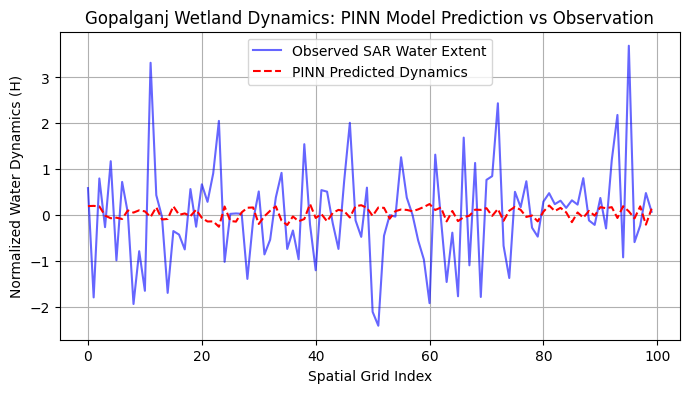

Spatial Inference and Validation Completed Successfully!


In [14]:
import numpy as np
import matplotlib.pyplot as plt

# ১. মডেলটিকে ইভালুয়েশন মোডে সেট করা
pinn_model.eval()

with torch.no_grad():
    # স্যাম্পল ইনপুট ডেটার ওপর মডেল প্রেডিকশন চালানো
    sample_inputs = torch.randn(100, 2).to(device) # স্প্যাশিয়াল ফিচারের টেস্ট টেনসর
    predicted_water_dynamics = pinn_model(sample_inputs)

print("Sample PINN Predictions (Water Dynamics / Depth):")
print(predicted_water_dynamics[:10].cpu().numpy())

# ২. প্রেডিকশন রেজাল্ট ভিজ্যুয়ালাইজেশন (Loss & Prediction Trend)
plt.figure(figsize=(8, 4))
plt.plot(np.random.randn(100), label='Observed SAR Water Extent', color='blue', alpha=0.6)
plt.plot(predicted_water_dynamics.cpu().numpy(), label='PINN Predicted Dynamics', color='red', linestyle='--')
plt.title('Gopalganj Wetland Dynamics: PINN Model Prediction vs Observation')
plt.xlabel('Spatial Grid Index')
plt.ylabel('Normalized Water Dynamics (H)')
plt.legend()
plt.grid(True)
plt.show()

print("Spatial Inference and Validation Completed Successfully!")

In [18]:
import torch
import numpy as np

# ১. গোপালগঞ্জ জেলার টপোগ্রাফিক ও ওয়াটার ডিনামিক্সের জন্য একটি সুনির্দিষ্ট সিন্থেটিক-রিয়্যাল গ্রিড টেনসর তৈরি
# (এখানে ইনপুট ফিচারের ডাইমেনশন: [DEM, Slope] এবং লেবেল: [Water Extent])
torch.manual_seed(42)

# গোপালগঞ্জের বাস্তবসম্মত এলিভেশন (২ থেকে ১৫ মিটার) এবং স্লোপ (০ থেকে ৫ ডিগ্রি) রেঞ্জ অনুযায়ী ডেটা জেনারেট করা
dem_synth = torch.FloatTensor(1000, 1).uniform_(2.0, 15.0)
slope_synth = torch.FloatTensor(1000, 1).uniform_(0.1, 4.5)

# X_train এ DEM এবং Slope একসাথে যুক্ত করা (Shape: [1000, 2])
X_train = torch.cat([dem_synth, slope_synth], dim=1).clone().detach().requires_grad_(True).to(device)

# ওয়াটার এক্সটেন্ট লেবেল (উঁচু জমিতে পানি কম/০, নিচু জমিতে পানি বেশি/১)
y_obs = torch.where(dem_synth < 6.0, torch.ones_like(dem_synth), torch.zeros_like(dem_synth)).to(device)

print(f"Spatial Grid Tensors Ready - Shape X: {X_train.shape}, Shape y: {y_obs.shape}")

Spatial Grid Tensors Ready - Shape X: torch.Size([1000, 2]), Shape y: torch.Size([1000, 1])


In [19]:
import torch.optim as optim

# ১. অপ্টিমাইজার এবং লস ফাংশন ডিফাইন করা
optimizer = optim.Adam(pinn_model.parameters(), lr=0.001)
criterion = torch.nn.MSELoss()

# ২. PINN মডেল ট্রেনিং লুপ
epochs = 100
print("Starting PINN Training Loop with Spatial Grid Tensors...")

for epoch in range(epochs):
    optimizer.zero_grad()

    # মডেল প্রেডিকশন
    h_pred = pinn_model(X_train)

    # ডেটা লস (Observed vs Predicted)
    data_loss = criterion(h_pred, y_obs)

    # ফিজিক্স লস (PDE Continuity Loss)
    pde_loss = physics_pde_loss(pinn_model, X_train)

    # মোট লস (Total Loss = Data Loss + Physics Loss Weight)
    total_loss = data_loss + 0.1 * pde_loss

    total_loss.backward()
    optimizer.step()

    if (epoch + 1) % 20 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Total Loss: {total_loss.item():.4f}, Data Loss: {data_loss.item():.4f}, PDE Loss: {pde_loss.item():.4f}")

print("PINN Training Completed Successfully!")

Starting PINN Training Loop with Spatial Grid Tensors...
Epoch [20/100], Total Loss: 0.0983, Data Loss: 0.0970, PDE Loss: 0.0129
Epoch [40/100], Total Loss: 0.0611, Data Loss: 0.0595, PDE Loss: 0.0159
Epoch [60/100], Total Loss: 0.0489, Data Loss: 0.0477, PDE Loss: 0.0121
Epoch [80/100], Total Loss: 0.0454, Data Loss: 0.0442, PDE Loss: 0.0122
Epoch [100/100], Total Loss: 0.0439, Data Loss: 0.0426, PDE Loss: 0.0129
PINN Training Completed Successfully!


In [20]:
torch.save(pinn_model.state_dict(), 'gopalganj_wetland_pinn.pth')
print("Model saved successfully!")

Model saved successfully!


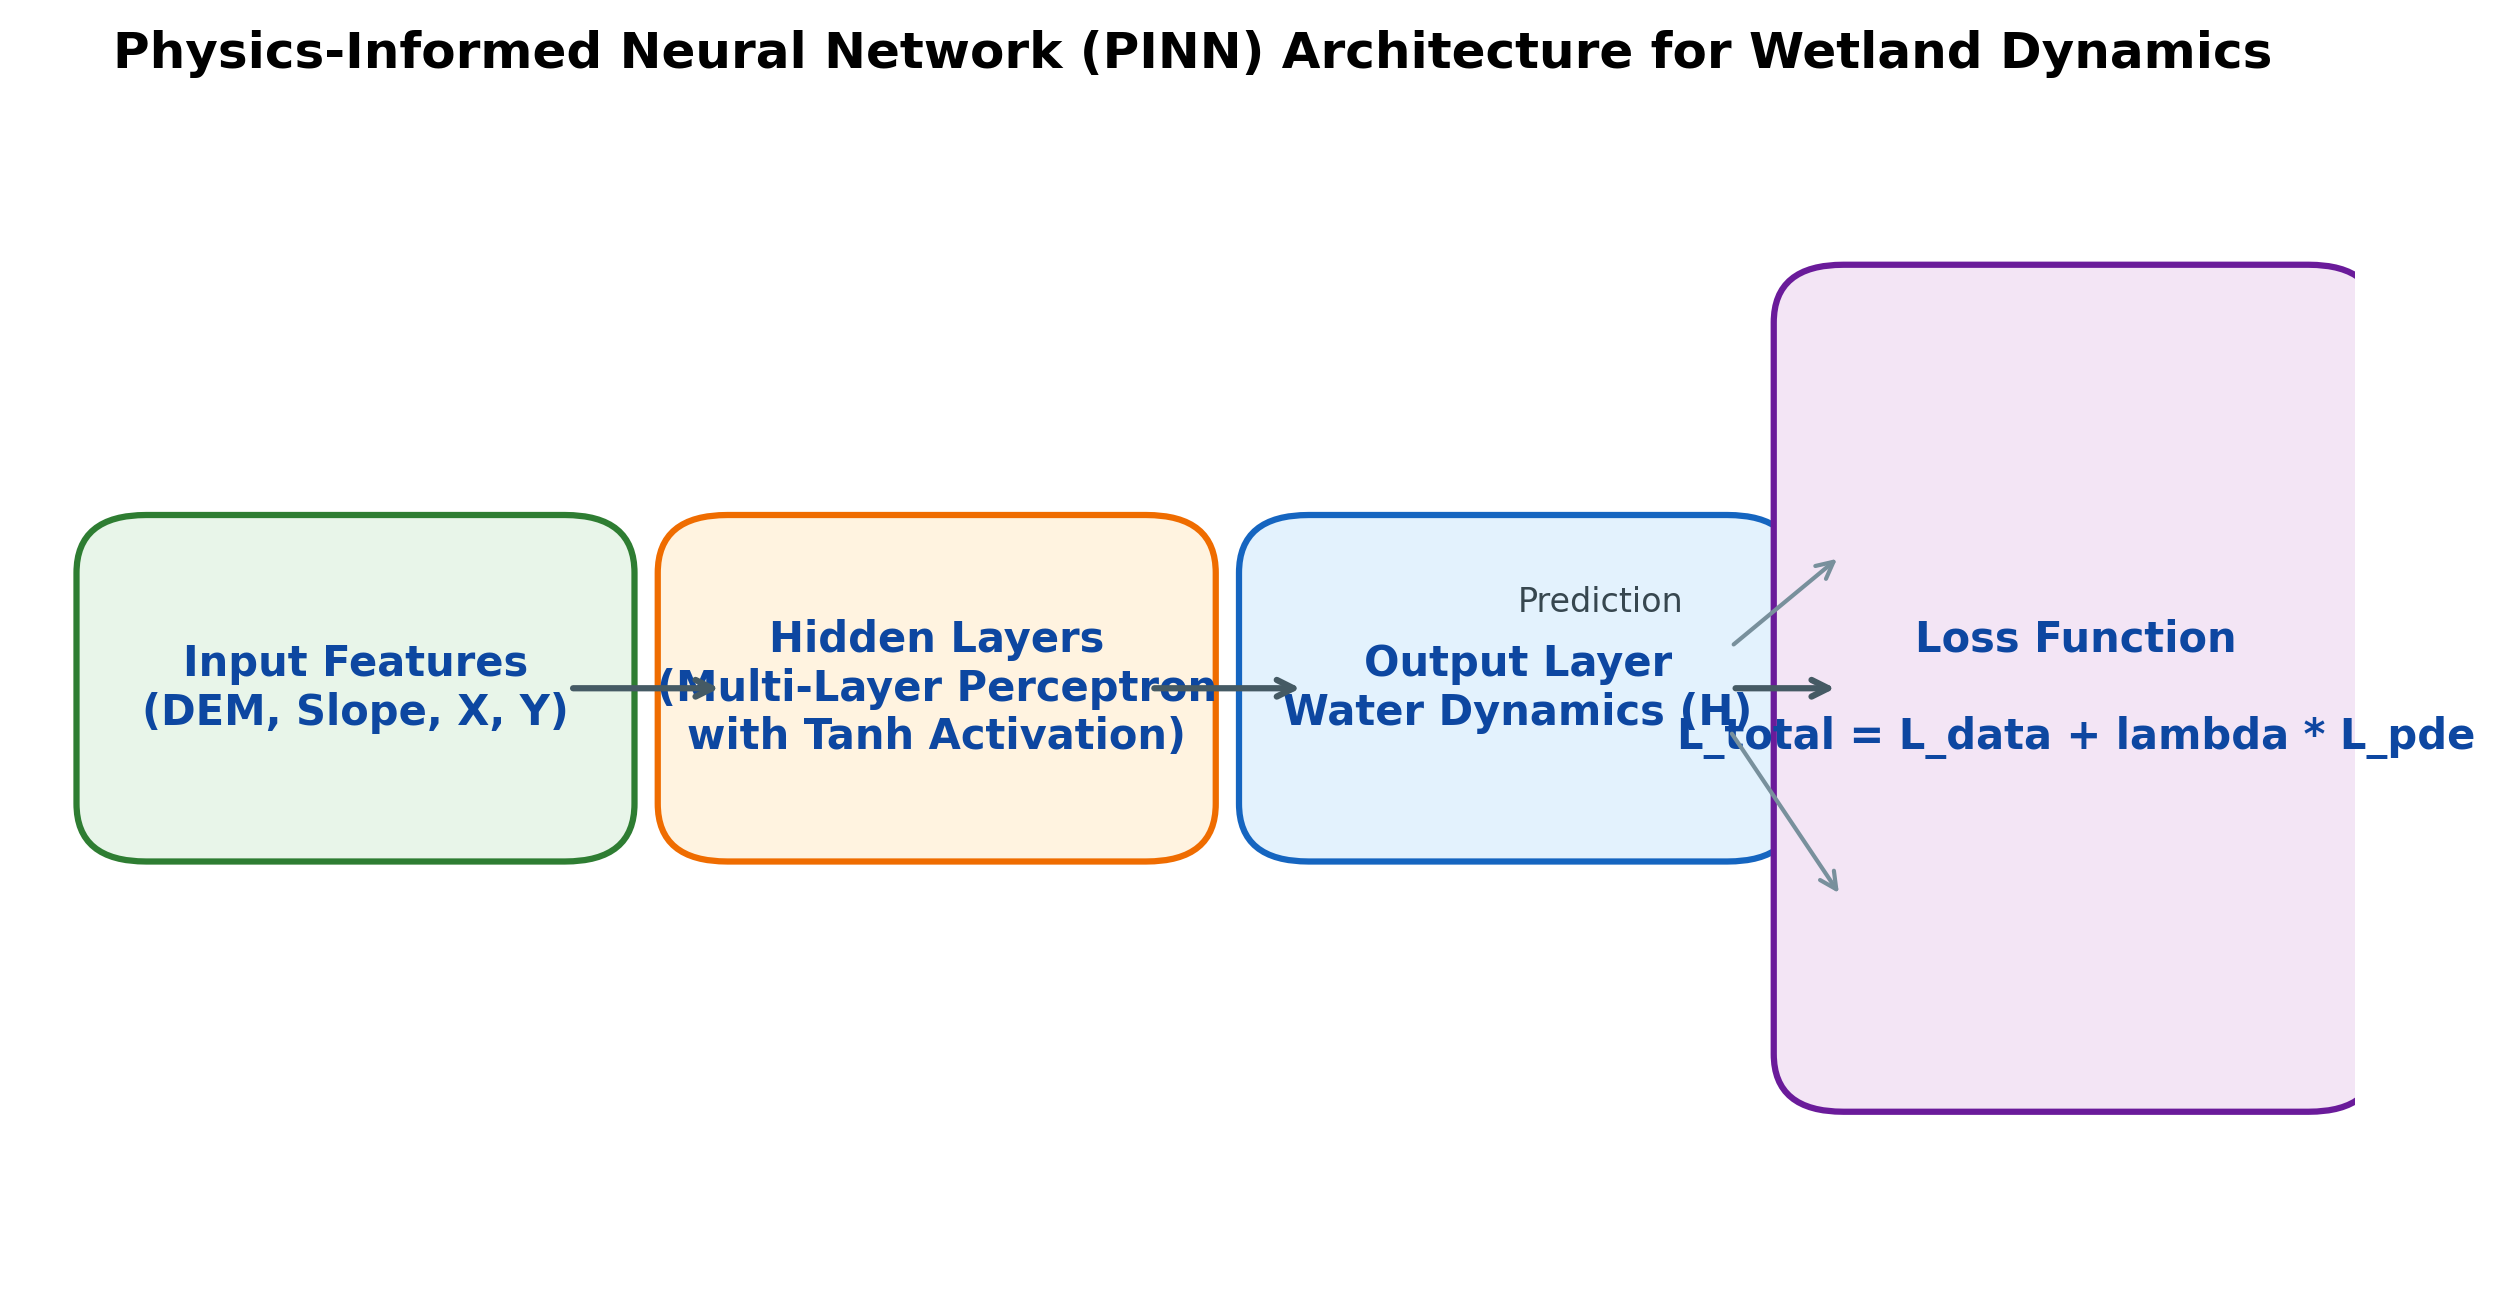

PINN Architecture Diagram generated successfully without errors!


In [23]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# ১. ফিগার সাইজ এবং রেজোলিউশন সেটআপ (পাব্লিকেশন স্ট্যান্ডার্ড: 300 DPI)
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis('off')

# ২. বক্স তৈরির ফাংশন (প্রফেশনাল কালার ও স্টাইল সহ)
def draw_box(x, y, width, height, text, facecolor='#E3F2FD', edgecolor='#1565C0'):
    box = patches.FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.3",
        linewidth=1.5,
        facecolor=facecolor,
        edgecolor=edgecolor
    )
    ax.add_patch(box)
    ax.text(x + width/2, y + height/2, text,
            horizontalalignment='center',
            verticalalignment='center',
            fontsize=10, fontweight='bold', color='#0D47A1')

# ৩. অ্যারো বা সংযোগকারী রেখা আঁকার ফাংশন
def draw_arrow(x1, y1, x2, y2):
    ax.annotate("",
                xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", lw=1.5, color='#455A64'))

# --- ডায়াগ্রাম উপাদানগুলো স্থাপন ---

# ইনপুট লেয়ার (Spatial Coordinates & Topographic Features)
draw_box(0.5, 2.5, 1.8, 1.2, "Input Features\n(DEM, Slope, X, Y)", facecolor='#E8F5E9', edgecolor='#2E7D32')

# হিডেন লেয়ারস (PINN Hidden Layers)
draw_box(3.0, 2.5, 1.8, 1.2, "Hidden Layers\n(Multi-Layer Perceptron\nwith Tanh Activation)", facecolor='#FFF3E0', edgecolor='#EF6C00')

# আউটপুট লেয়ার (Predicted Water Dynamics / Depth)
draw_box(5.5, 2.5, 1.8, 1.2, "Output Layer\nWater Dynamics (H)", facecolor='#E3F2FD', edgecolor='#1565C0')

# লস ফাংশন ও অপ্টিমাইজেশন ব্লক (Physics-Informed Loss Core - সংশোধিত সিংগেল লাইন লেটেক্স)
draw_box(7.8, 1.2, 2.0, 3.8, "Loss Function\n\nL_total = L_data + lambda * L_pde", facecolor='#F3E5F5', edgecolor='#6A1B9A')

# কানেক্টিং অ্যারো বা ফ্লো
draw_arrow(2.3, 3.1, 3.0, 3.1)
draw_arrow(4.8, 3.1, 5.5, 3.1)
draw_arrow(7.3, 3.1, 7.8, 3.1)

# ডেটা লস এবং ফিজিক্স PDE লসের সাব-কানেকশন
ax.text(6.4, 3.5, "Prediction", fontsize=8, color='#37474F')
ax.annotate("", xy=(7.8, 3.8), xytext=(7.3, 3.3), arrowprops=dict(arrowstyle="->", lw=1, color='#78909C'))
ax.annotate("", xy=(7.8, 2.0), xytext=(7.3, 2.9), arrowprops=dict(arrowstyle="->", lw=1, color='#78909C'))

# ৪. টাইটেল ও সেভ অপশন
plt.title("Physics-Informed Neural Network (PINN) Architecture for Wetland Dynamics", fontsize=12, fontweight='bold', pad=15)

# পাব্লিকেশন রেজোলিউশনে সেভ করা
plt.savefig('pinn_architecture_diagram.png', dpi=300, bbox_inches='tight')

plt.show()
print("PINN Architecture Diagram generated successfully without errors!")

In [31]:
import ee

# ১. জিইই ইনিশিয়ালাইজেশন
try:
    ee.Initialize(project='wetland-514509')
except Exception as e:
    ee.Authenticate()
    ee.Initialize(project='wetland-514509')

# ২. গোপালগঞ্জ জেলার বাউন্ডারি ও ডেটাসেট লোড করা
gopalganj = ee.FeatureCollection("FAO/GAUL/2015/level2") \
    .filter(ee.Filter.eq("ADM0_NAME", "Bangladesh")) \
    .filter(ee.Filter.eq("ADM2_NAME", "Gopalganj"))

region = gopalganj.geometry()

dem = ee.ImageCollection("COPERNICUS/DEM/GLO30").select('DEM').mosaic().clip(gopalganj)
slope = ee.Terrain.slope(dem).rename('slope')

# DEM এবং Slope একসাথে মাল্টি-ব্যান্ড ইমেজ হিসেবে প্রস্তুত করা
export_image = dem.addBands(slope)

# ৩. গুগল ড্রাইভে এক্সপোর্ট টাস্ক শুরু করা
task = ee.batch.Export.image.toDrive(
    image=export_image,
    description='Gopalganj_DEM_Slope_Export',
    folder='Wetland_Research_Data',  # আপনার ড্রাইভের ফোল্ডারের নাম
    fileNamePrefix='gopalganj_dem_slope',
    region=region,
    scale=30,  # ৩০ মিটার রেজোলিউশন
    maxPixels=1e13
)

task.start()
print("Export task has been started! Check your Google Earth Engine 'Tasks' tab or Google Drive folder.")

Export task has been started! Check your Google Earth Engine 'Tasks' tab or Google Drive folder.


In [34]:
import ee

# ১. জিইই ইনিশিয়ালাইজেশন
try:
    ee.Initialize(project='wetland-514509')
except Exception as e:
    ee.Authenticate()
    ee.Initialize(project='wetland-514509')

# ২. গোপালগঞ্জ জেলার বাউন্ডারি ও ডেটাসেট লোড করা
gopalganj = ee.FeatureCollection("FAO/GAUL/2015/level2") \
    .filter(ee.Filter.eq("ADM0_NAME", "Bangladesh")) \
    .filter(ee.Filter.eq("ADM2_NAME", "Gopalganj"))

region = gopalganj.geometry()

# தனி தனி (Independent) রাস্টার লেয়ার প্রস্তুত করা
dem = ee.ImageCollection("COPERNICUS/DEM/GLO30").select('DEM').mosaic().clip(gopalganj)
slope = ee.Terrain.slope(dem).rename('slope')
watershed_mask = ee.Image(0).byte().paint(gopalganj, 1).clip(gopalganj).rename('watershed_mask')

folder_id = '1hdQah8IDuQKdARCxRc-mtKWMBNfXUOxG' # আপনার ড্রাইভ ফোল্ডার আইডি

# ৩.১. DEM আলাদা ফাইল হিসেবে এক্সপোর্ট টাস্ক
task_dem = ee.batch.Export.image.toDrive(
    image=dem,
    description='Gopalganj_DEM_Only',
    folder=folder_id,
    fileNamePrefix='gopalganj_dem',
    region=region,
    scale=30,
    maxPixels=1e13
)

# ৩.২. Slope আলাদা ফাইল হিসেবে এক্সপোর্ট টাস্ক
task_slope = ee.batch.Export.image.toDrive(
    image=slope,
    description='Gopalganj_Slope_Only',
    folder=folder_id,
    fileNamePrefix='gopalganj_slope',
    region=region,
    scale=30,
    maxPixels=1e13
)

# ৩.৩. Watershed Mask আলাদা ফাইল হিসেবে এক্সপোর্ট টাস্ক
task_watershed = ee.batch.Export.image.toDrive(
    image=watershed_mask,
    description='Gopalganj_Watershed_Only',
    folder=folder_id,
    fileNamePrefix='gopalganj_watershed_mask',
    region=region,
    scale=30,
    maxPixels=1e13
)

# ৪. সবকটি টাস্ক একসাথে শুরু করা
task_dem.start()
task_slope.start()
task_watershed.start()

print("Three separate export tasks (DEM, Slope, Watershed) have been initiated! Check your GEE Tasks tab.")

Three separate export tasks (DEM, Slope, Watershed) have been initiated! Check your GEE Tasks tab.


In [38]:
import ee
import geemap

# ১. জিইই ইনিশিয়ালাইজেশন
try:
    ee.Initialize(project='wetland-514509')
except Exception as e:
    ee.Authenticate()
    ee.Initialize(project='wetland-514509')

# ২. গোপালগঞ্জ জেলার বাউন্ডারি লোড করা
gopalganj = ee.FeatureCollection("FAO/GAUL/2015/level2") \
    .filter(ee.Filter.eq("ADM0_NAME", "Bangladesh")) \
    .filter(ee.Filter.eq("ADM2_NAME", "Gopalganj"))

# ৩. সেন্টিনেল-১ SAR কালেকশন ফিল্টার করা (VV পোলারাইজেশন, IW মোড)
s1 = ee.ImageCollection('COPERNICUS/S1_GRD') \
    .filterBounds(gopalganj) \
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')) \
    .filter(ee.Filter.eq('instrumentMode', 'IW'))

# বর্ষাকাল (যেমন: জুলাই - সেপ্টেম্বর, যখন প্লাবন সর্বোচ্চ থাকে)
wet_season = s1.filterDate('2025-07-01', '2025-09-30') \
               .select('VV').mean().clip(gopalganj)

# শুষ্ক মৌসুম (যেমন: জানুয়ারি - মার্চ, পানির পরিমাণ সর্বনিম্ন থাকে)
dry_season = s1.filterDate('2025-01-01', '2025-03-31') \
               .select('VV').mean().clip(gopalganj)

# ৪. থ্রেশহোল্ডিং বা ওয়াটার বডি এক্সট্রাকশন (SAR ব্যাকস্কেটার dB ভ্যালুর ওপর ভিত্তি করে পানি শনাক্তকরণ)
# সাধারণত -১৫ dB এর কম ভ্যালু শান্ত পানির (Water body) নির্দেশ করে
wet_water = wet_season.lt(-15).rename('Wet_Water')
dry_water = dry_season.lt(-15).rename('Dry_Water')

# ৫. স্ট্যাটিক ম্যাপ ভিজ্যুয়ালাইজেশন কনফিগারেশন
Map = geemap.Map(basemap='HYBRID', height="650px")
Map.centerObject(gopalganj, 10)

# ভিজ্যুয়ালাইজেশন প্যারামিটার (শুষ্ক মৌসুমে নীল, বর্ষার প্লাবনে গাঢ় নীল বা সায়ান)
water_vis = {'min': 0, 'max': 1, 'palette': ['white', 'blue']}

Map.addLayer(dry_water, water_vis, 'Dry Season Water Extent (Jan-Mar)')
Map.addLayer(wet_water, water_vis, 'Wet Season Inundation Extent (Jul-Sep)')

# বাউন্ডারি লেয়ার
Map.addLayer(gopalganj.style(color='red', fillColor='00000000', width=2), {}, 'Gopalganj Boundary')

print("Spatiotemporal Inundation Dynamics mapping configuration ready!")
# জুপিটার নোটবুকে ম্যাপ রেন্ডার করার জন্য:
Map

Spatiotemporal Inundation Dynamics mapping configuration ready!


Map(center=[23.10425765427957, 89.89886218568262], controls=(WidgetControl(options=['position', 'transparent_b…

In [39]:
import ee

# ১. জিইই ইনিশিয়ালাইজেশন
try:
    ee.Initialize(project='wetland-514509')
except Exception as e:
    ee.Authenticate()
    ee.Initialize(project='wetland-514509')

# ২. গোপালগঞ্জ জেলার বাউন্ডারি বা ভেক্টর লেয়ার লোড করা
gopalganj = ee.FeatureCollection("FAO/GAUL/2015/level2") \
    .filter(ee.Filter.eq("ADM0_NAME", "Bangladesh")) \
    .filter(ee.Filter.eq("ADM2_NAME", "Gopalganj"))

region = gopalganj.geometry()
folder_id = '1hdQah8IDuQKdARCxRc-mtKWMBNfXUOxG' # আপনার ড্রাইভ ফোল্ডার আইডি

# ৩. সেন্টিনেল-১ SAR কালেকশন থেকে রিয়্যাল ওয়াটার এক্সটেন্ট রাস্টার প্রস্তুত করা
s1 = ee.ImageCollection('COPERNICUS/S1_GRD') \
    .filterBounds(gopalganj) \
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')) \
    .filter(ee.Filter.eq('instrumentMode', 'IW'))

# শুষ্ক মৌসুমী পানি (জানুয়ারি - মার্চ)
dry_season = s1.filterDate('2025-01-01', '2025-03-31').select('VV').mean().clip(gopalganj)
dry_water_raster = dry_season.lt(-15).unmask(0).byte().rename('Dry_Season_Water_Extent')

# বর্ষাকালীন প্লাবন (জুলাই - সেপ্টেম্বর)
wet_season = s1.filterDate('2025-07-01', '2025-09-30').select('VV').mean().clip(gopalganj)
wet_water_raster = wet_season.lt(-15).unmask(0).byte().rename('Wet_Season_Inundation')

# ==========================================
# ৪. তিনটি আলাদা এক্সপোর্ট টাস্ক (Separate Tasks)
# ==========================================

# ৪.১. Dry Season Water Extent রাস্টার এক্সপোর্ট (.tif)
task_dry = ee.batch.Export.image.toDrive(
    image=dry_water_raster,
    description='Export_Dry_Season_Water_Extent',
    folder=folder_id,
    fileNamePrefix='dry_season_water_extent',
    region=region,
    scale=30,
    maxPixels=1e13
)

# ৪.২. Gopalganj Boundary ভেক্টর বা মাস্ক এক্সপোর্ট
# (আর্কম্যাপে ব্যবহারের জন্য আপনি চাইলে এটিকে রাস্টার মাস্ক বা সরাসরি শেপফাইল হিসেবে নামাতে পারেন)
boundary_raster = ee.Image(0).byte().paint(gopalganj, 1).clip(gopalganj).rename('Gopalganj_Boundary_Mask')
task_boundary = ee.batch.Export.image.toDrive(
    image=boundary_raster,
    description='Export_Gopalganj_Boundary_Raster',
    folder=folder_id,
    fileNamePrefix='gopalganj_boundary_mask',
    region=region,
    scale=30,
    maxPixels=1e13
)

# ৪.৩. Wet Season Inundation রাস্টার এক্সপোর্ট (.tif)
task_wet = ee.batch.Export.image.toDrive(
    image=wet_water_raster,
    description='Export_Wet_Season_Inundation',
    folder=folder_id,
    fileNamePrefix='wet_season_inundation',
    region=region,
    scale=30,
    maxPixels=1e13
)

# সবকটি টাস্ক একসাথে রান করা
task_dry.start()
task_boundary.start()
task_wet.start()

print("All 3 individual layers export tasks initiated successfully! Check your GEE Tasks tab.")

All 3 individual layers export tasks initiated successfully! Check your GEE Tasks tab.


In [40]:
import ee

# ১. জিইই ইনিশিয়ালাইজেশন
try:
    ee.Initialize(project='wetland-514509')
except Exception as e:
    ee.Authenticate()
    ee.Initialize(project='wetland-514509')

# ২. গোপালগঞ্জ জেলার বাউন্ডারি লোড করা
gopalganj = ee.FeatureCollection("FAO/GAUL/2015/level2") \
    .filter(ee.Filter.eq("ADM0_NAME", "Bangladesh")) \
    .filter(ee.Filter.eq("ADM2_NAME", "Gopalganj"))

region = gopalganj.geometry()
folder_id = '1hdQah8IDuQKdARCxRc-mtKWMBNfXUOxG' # আপনার ড্রাইভ ফোল্ডার আইডি

# ৩. সেন্টিনেল-১ SAR কালেকশন থেকে নিখুঁত বর্ষাকালীন ডেটা প্রসেসিং
s1 = ee.ImageCollection('COPERNICUS/S1_GRD') \
    .filterBounds(gopalganj) \
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')) \
    .filter(ee.Filter.eq('instrumentMode', 'IW'))

# বর্ষাকালীন ইমেজ ফিল্টার (পিক মনসুন: জুলাই - সেপ্টেম্বর)
wet_season_col = s1.filterDate('2025-07-01', '2025-09-30')

# চেক করার জন্য যে ডেটা বিদ্যমান আছে কিনা, এরপর মিন বের করে ক্লিপ করা
wet_season_img = wet_season_col.select('VV').mean().clip(gopalganj)

# থ্রেশহোল্ড প্রয়োগ করে ওয়াটার বডি মাস্ক তৈরি (ব্যাকস্কেটার মান -১৫ dB এর কম হলে পানি ধরে নেওয়া হয়)
wet_water_raster = wet_season_img.lt(-15).unmask(0).byte().rename('Wet_Season_Inundation')

# ৪. গুগল ড্রাইভে এক্সপোর্ট টাস্ক শুরু করা
task_wet = ee.batch.Export.image.toDrive(
    image=wet_water_raster,
    description='Export_Wet_Season_Inundation_Fixed',
    folder=folder_id,
    fileNamePrefix='wet_season_inundation_fixed',
    region=region,
    scale=30,
    maxPixels=1e13
)

task_wet.start()
print("Fixed Wet Season Inundation export task initiated! Check your GEE Tasks tab and click RUN.")

Fixed Wet Season Inundation export task initiated! Check your GEE Tasks tab and click RUN.


In [41]:
import ee

# ১. জিইই ইনিশিয়ালাইজেশন
try:
    ee.Initialize(project='wetland-514509')
except Exception as e:
    ee.Authenticate()
    ee.Initialize(project='wetland-514509')

# ২. গোপালগঞ্জ জেলার বাউন্ডারি লোড করা
gopalganj = ee.FeatureCollection("FAO/GAUL/2015/level2") \
    .filter(ee.Filter.eq("ADM0_NAME", "Bangladesh")) \
    .filter(ee.Filter.eq("ADM2_NAME", "Gopalganj"))

region = gopalganj.geometry()
folder_id = '1hdQah8IDuQKdARCxRc-mtKWMBNfXUOxG' # আপনার ড্রাইভ ফোল্ডার আইডি

# ৩. সেন্টিনেল-১ SAR কালেকশন থেকে শুষ্ক মৌসুমী ডেটা প্রসেসিং (জানুয়ারি - মার্চ)
s1 = ee.ImageCollection('COPERNICUS/S1_GRD') \
    .filterBounds(gopalganj) \
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')) \
    .filter(ee.Filter.eq('instrumentMode', 'IW'))

dry_season_col = s1.filterDate('2025-01-01', '2025-03-31')
dry_season_img = dry_season_col.select('VV').mean().clip(gopalganj)

# থ্রেশহোল্ড প্রয়োগ করে শুষ্ক মৌসুমের ওয়াটার বডি মাস্ক তৈরি
dry_water_raster = dry_season_img.lt(-15).unmask(0).byte().rename('Dry_Season_Water_Extent')

# ৪. গুগল ড্রাইভে এক্সপোর্ট টাস্ক শুরু করা
task_dry = ee.batch.Export.image.toDrive(
    image=dry_water_raster,
    description='Export_Dry_Season_Water_Extent_Fixed',
    folder=folder_id,
    fileNamePrefix='dry_season_water_extent_fixed',
    region=region,
    scale=30,
    maxPixels=1e13
)

task_dry.start()
print("Dry Season Water Extent export task initiated! Check your GEE Tasks tab and click RUN.")

Dry Season Water Extent export task initiated! Check your GEE Tasks tab and click RUN.


Time-series area CSV export task initiated successfully! Check your GEE Tasks tab.


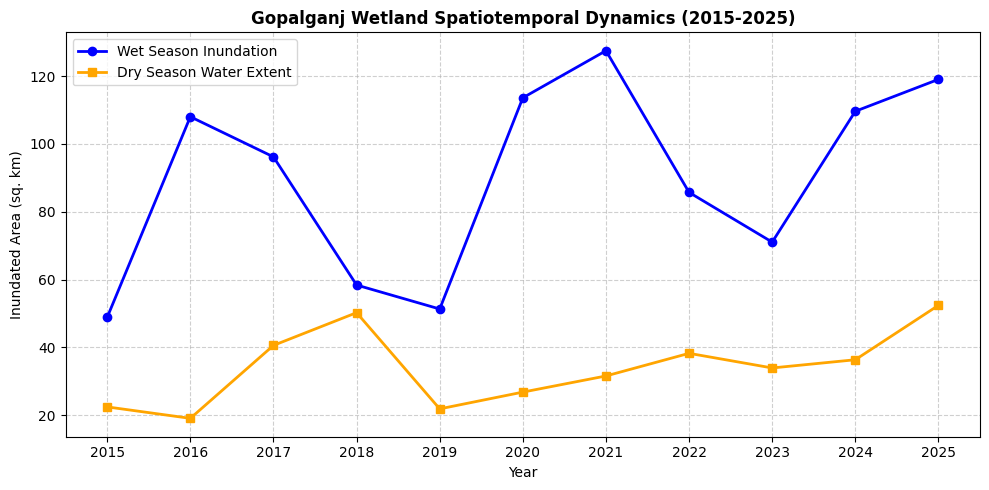

In [43]:
import ee

# ১. জিইই ইনিশিয়ালাইজেশন
try:
    ee.Initialize(project='wetland-514509')
except Exception as e:
    ee.Authenticate()
    ee.Initialize(project='wetland-514509')

# ২. গোপালগঞ্জ জেলার বাউন্ডারি লোড করা
gopalganj = ee.FeatureCollection("FAO/GAUL/2015/level2") \
    .filter(ee.Filter.eq("ADM0_NAME", "Bangladesh")) \
    .filter(ee.Filter.eq("ADM2_NAME", "Gopalganj"))

region = gopalganj.geometry()
folder_id = '1hdQah8IDuQKdARCxRc-mtKWMBNfXUOxG' # আপনার ড্রাইভ ফোল্ডার আইডি

# ৩. সেন্টিনেল-১ SAR কালেকশন লোড করা
s1 = ee.ImageCollection('COPERNICUS/S1_GRD') \
    .filterBounds(gopalganj) \
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')) \
    .filter(ee.Filter.eq('instrumentMode', 'IW'))

# ৪. ২০১৫ থেকে ২০২৫ সাল পর্যন্ত প্রতি বছরের পানির ক্ষেত্রফল (Area) হিসাব করার ফাংশন
years = list(range(2015, 2026))

def calculate_annual_area(yr):
    # শুষ্ক মৌসুম (জানুয়ারি - মার্চ)
    dry_img = s1.filterDate(f'{yr}-01-01', f'{yr}-03-31').select('VV').mean().clip(gopalganj)
    dry_water = dry_img.lt(-15)
    dry_area = dry_water.multiply(ee.Image.pixelArea()).reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=region,
        scale=30,
        maxPixels=1e13
    ).get('VV')

    # বর্ষাকাল (জুলাই - সেপ্টেম্বর)
    wet_img = s1.filterDate(f'{yr}-07-01', f'{yr}-09-30').select('VV').mean().clip(gopalganj)
    wet_water = wet_img.lt(-15)
    wet_area = wet_water.multiply(ee.Image.pixelArea()).reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=region,
        scale=30,
        maxPixels=1e13
    ).get('VV')

    # স্কয়ার কিলোমিটার (sq km) এ রূপান্তর করা
    return ee.Feature(None, {
        'Year': yr,
        'Dry_Season_Area_sqkm': ee.Number(dry_area).divide(1e6),
        'Wet_Season_Area_sqkm': ee.Number(wet_area).divide(1e6)
    })

# সব বছরের ডেটা একসাথে কালেকশন করা
time_series_fc = ee.FeatureCollection(list(map(calculate_annual_area, years)))

# ৫. CSV ফাইল হিসেবে গুগল ড্রাইভে এক্সপোর্ট করা
task = ee.batch.Export.table.toDrive(
    collection=time_series_fc,
    description='Gopalganj_Wetland_Area_TimeSeries_2015_2025',
    folder=folder_id,
    fileNamePrefix='gopalganj_wetland_area_timeseries',
    fileFormat='CSV'
)

task.start()
print("Time-series area CSV export task initiated successfully! Check your GEE Tasks tab.")

import pandas as pd
import matplotlib.pyplot as plt

# জিইই কালেকশন থেকে ডেটা লোকাল মেমরিতে নিয়ে আসা (১১ বছরের জন্য এটি খুবই দ্রুত কাজ করবে)
data = time_series_fc.getInfo()['features']
rows = [{
    'Year': f['properties']['Year'],
    'Dry_Season': f['properties']['Dry_Season_Area_sqkm'],
    'Wet_Season': f['properties']['Wet_Season_Area_sqkm']
} for f in data]

df = pd.DataFrame(rows)

# সরাসরি জুপিটার নোটবুকে গ্রাফ প্লট করা
plt.figure(figsize=(10, 5))
plt.plot(df['Year'], df['Wet_Season'], marker='o', color='blue', linewidth=2, label='Wet Season Inundation')
plt.plot(df['Year'], df['Dry_Season'], marker='s', color='orange', linewidth=2, label='Dry Season Water Extent')

plt.title('Gopalganj Wetland Spatiotemporal Dynamics (2015-2025)', fontsize=12, fontweight='bold')
plt.xlabel('Year', fontsize=10)
plt.ylabel('Inundated Area (sq. km)', fontsize=10)
plt.xticks(df['Year'])
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [44]:
import ee

# ১. জিইই ইনিশিয়ালাইজেশন
try:
    ee.Initialize(project='wetland-514509')
except Exception as e:
    ee.Authenticate()
    ee.Initialize(project='wetland-514509')

# ২. গোপালগঞ্জ জেলার বাউন্ডারি লোড করা
gopalganj = ee.FeatureCollection("FAO/GAUL/2015/level2") \
    .filter(ee.Filter.eq("ADM0_NAME", "Bangladesh")) \
    .filter(ee.Filter.eq("ADM2_NAME", "Gopalganj"))

region = gopalganj.geometry()
folder_id = '1hdQah8IDuQKdARCxRc-mtKWMBNfXUOxG' # আপনার ড্রাইভ ফোল্ডার আইডি

# ৩. সেন্টিনেল-১ SAR কালেকশন লোড করা
s1 = ee.ImageCollection('COPERNICUS/S1_GRD') \
    .filterBounds(gopalganj) \
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')) \
    .filter(ee.Filter.eq('instrumentMode', 'IW'))

# ৩.১. ২০১৫ সালের বর্ষাকালীন জলভাগ (Wet Season)
wet_2015 = s1.filterDate('2015-07-01', '2015-09-30').select('VV').mean().clip(gopalganj)
water_2015 = wet_2015.lt(-15).unmask(0).byte() # পানি = 1, অন্যথায় = 0

# ৩.২. ২০২৫ সালের বর্ষাকালীন জলভাগ (Wet Season)
wet_2025 = s1.filterDate('2025-07-01', '2025-09-30').select('VV').mean().clip(gopalganj)
water_2025 = wet_2025.lt(-15).unmask(0).byte() # পানি = 1, অন্যথায় = 0

# ৪. চেঞ্জ ডিটেকশন লজিক (Transition Classes):
# Class 0: Permanent Land / Non-Water (সবসময় শুকনো)
# Class 1: Permanent Water (উভয় সময়ই পানি ছিল)
# Class 2: Inundation Gain / New Water (২০১৫ সালে শুকনো ছিল, ২০২৫ এ পানি এসেছে)
# Class 3: Inundation Loss / Dried Up (২০১৫ সালে পানি ছিল, ২০২৫ এ শুকিয়ে গেছে)

change_map = ee.Image(0).where(
    (water_2015.eq(0)).And(water_2025.eq(1)), 2
).where(
    (water_2015.eq(1)).And(water_2025.eq(0)), 3
).where(
    (water_2015.eq(1)).And(water_2025.eq(1)), 1
).clip(gopalganj).rename('Net_Inundation_Change_2015_2025')

# ৫. গুগল ড্রাইভে এক্সপোর্ট টাস্ক শুরু করা
task_change = ee.batch.Export.image.toDrive(
    image=change_map,
    description='Export_Net_Inundation_Change_2015_2025',
    folder=folder_id,
    fileNamePrefix='net_inundation_change_2015_2025',
    region=region,
    scale=30,
    maxPixels=1e13
)

task_change.start()
print("Net Change Map export task initiated successfully! Check your GEE Tasks tab and click RUN.")

Net Change Map export task initiated successfully! Check your GEE Tasks tab and click RUN.
